In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from shared import CODED_CSV, TRENDS_CSV, NATIVE, LUME, NEUTRAL, GRID, save

In [ ]:
tr = pd.read_csv(TRENDS_CSV, index_col=0, parse_dates=True)
tr.tail()

,Native deodorant,Lume deodorant
date,,
2026-08-30,54,23
2026-09-06,52,21
2026-09-13,41,17
2026-09-20,26,13
2026-09-27,25,12


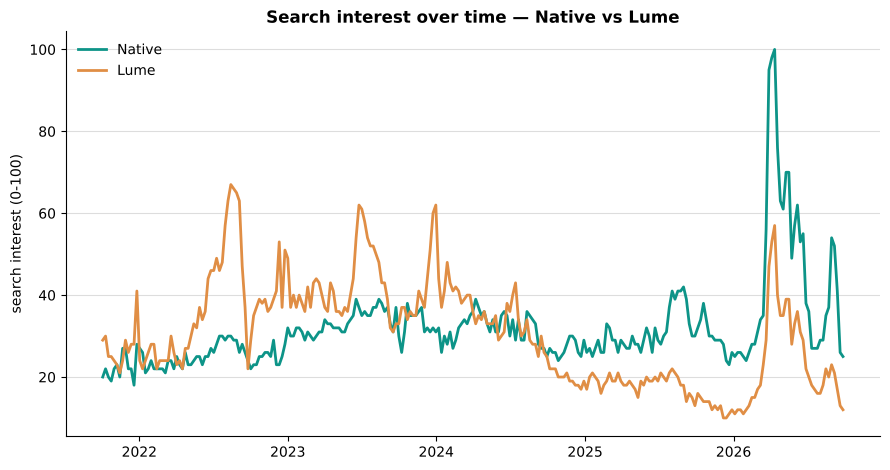

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(tr.index, tr["Native deodorant"], color=NATIVE, lw=2, label="Native")
ax.plot(tr.index, tr["Lume deodorant"], color=LUME, lw=2, label="Lume")
ax.set_ylabel("search interest (0-100)")
ax.set_title("Search interest over time — Native vs Lume", fontweight="bold")
ax.yaxis.grid(True, color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper left")
save(fig, "search_interest.png")

In [ ]:
nat = pd.read_csv(CODED_CSV, parse_dates=["date"])
nat = nat[nat["brand"] == "Native"]

series = (nat.dropna(subset=["date"]).sort_values("date")
             .set_index("date")["vader"]
             .resample("QE").mean().rolling(2).mean().dropna())
series.tail()

date
2025-09-30    0.202701
2025-12-31    0.235296
2026-03-31    0.258642
2026-06-30    0.161068
2026-09-30    0.156882
Freq: QE-DEC, Name: vader, dtype: float64

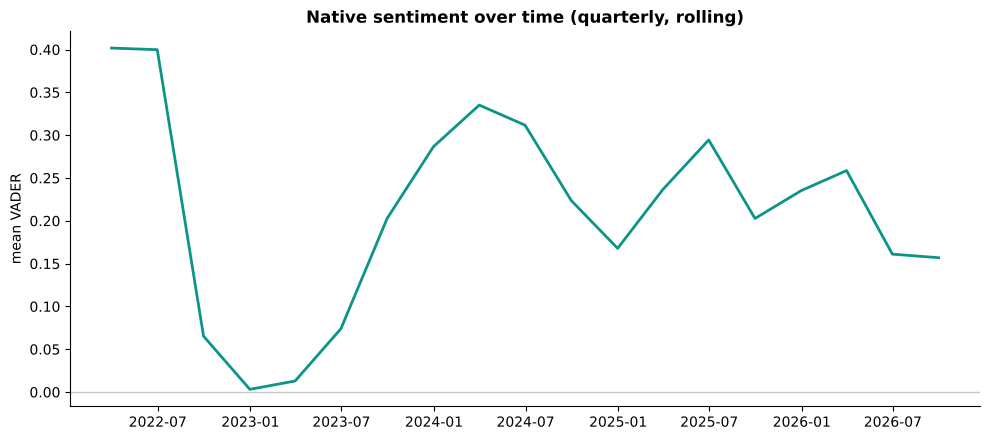

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(series.index, series.values, color=NATIVE, lw=2)
ax.axhline(0, color=NEUTRAL, lw=1)
ax.set_ylabel("mean VADER")
ax.set_title("Native sentiment over time (quarterly, rolling)", fontweight="bold")
save(fig, "sentiment_over_time.png")